# 04d — Does readout error add to the calibrated parameters the way 05–07 assume?

**Result.** Adding `p_meas` after calibrating with it off is legitimate, but two details of how
05 and 06c did it were wrong. Neither changes a conclusion.

| question | answer | evidence |
| --- | --- | --- |
| Does `p_meas` change the data cost `n_data` (so λ and `p`)? | **No** | `n_data` 6.86 vs 6.89 (d = 3), 8.34 vs 8.40 (d = 5): −0.14 and −0.36 SE (§2) |
| How does `p_meas` combine with the ancilla's own faults? | **As two independent flips, `a ⊕ b`.** 05/06c's rule `1 − (1−a)(1−b)` is wrong | at `p_meas = 0.3`: ⊕ gives χ²/dof 1.28 and 0.99; 05/06c's rule 27.5 and 53.1 (§3). At the operating point the two differ by 6×10⁻⁶ |
| How much does the final data readout's own error contribute? | **0.4–5.8% of `p_L`, growing with Δt; Δt\* moves by under 0.5σ** | theory with that readout noiseless against with `p_meas` (§4b) |
| Should the theory's final data readout carry `p_read`? | **No, `p_meas` only**: the data are measured directly | corrected theory `p_L` is 0.1–7.9% lower (about 4% on average); Δt\* at d = 3 moves 16.7 → 14.9 (Selene 12.0), at d = 5 5.7 → 5.9 (Selene 5.1) (§4) |

Also found on the way (§1b): Selene seeds shot `k` with `random_seed + shot_offset + k`, so runs
whose seed ranges overlap share their noise. 06c's `p_meas` sweep ran every `p_meas` at seed 1.

## Premise

Three sources, kept apart.

**Paper.** The readout fault is abstract: "the readout of the syndrome outcome s itself is
noisy, where its value is flipped with probability `p_read = b_read·p`". There is no ancilla
and no circuit in the paper's model.

**This repo.** `04` measured the cost of one extraction round in Selene **with `p_meas = 0`**
(Selene's default; `04` passes only `p_1q`). It exported `n_data` and `n_anc`, the charged ops
per round on a data qubit and on a Z-ancilla. `05` and `06c` then **add** `p_meas` analytically:

```
p_anc  = accumulate(n_anc, 2·p_1q/3)                    gate faults on the Z-ancilla
p_read = 1 − (1 − p_meas)(1 − p_anc)                     05 effective(), 06c effective()
```

and `06c`'s theory curve applies that `p_read` to **every** measurement, including the final
data readout (Stim's `before_measure_flip_probability`).

**What that assumes, and what is tested here.**

| | assumption | test |
| --- | --- | --- |
| Q1 | `p_meas` does not change the data cost `n_data`, so λ and `p` are unaffected | §2: 04's proxy with `p_meas` on, against 04's cached `p_meas = 0` runs |
| Q2 | the recorded Z-ancilla bit is the gate part and `p_meas` **composed as independent flips** | §3: Z-ancilla rate against two composition rules |
| Q3 | the theory's final data readout carries `p_read` | §4–5: rebuild the theory with `p_meas` alone on the final data readout, and compare both against 06c's stored Selene shots |

Two flips that both happen cancel, so independent composition is
`a ⊕ b = a + b − 2ab`. The formula used in 05/06c, `1 − (1 − a)(1 − b) = a + b − ab`, is the
probability that **at least one** happens; it over-counts by `ab`. Q2 tells the two apart by
raising `p_meas` until `ab` is resolvable.

## 0. Setup

The proxy circuit, the program generator and the Selene runner are copied **verbatim** from
`04` (§1–2 there), so the `p_meas = 0` reference points are read from 04's run cache under
04's own keys rather than re-run. New runs are cached under `04d_readout_composition`.

Environment: the venv the circuit-level notebooks were run in (selene-sim 0.3.0,
selene-hugr-qis-compiler 0.4.2, stim 1.16.0, pymatching 2.4.0); versions are printed below.

In [1]:
# ---- the knobs -------------------------------------------------------------
CODES      = [("rotated", 3), ("rotated", 5)]   # the two codes 06c measured
# Q1, data side: 04's exact settings, plus p_meas
P1Q        = 0.001          # 04's data-side p_1q
ROUNDS     = (1, 2, 4, 6, 8)
SHOTS      = 12000          # 04's shots per point
SEED       = 1              # 04's seed (the p_meas = 0 reference)
PMEAS_DATA = 0.02           # 10x the operating point: a flipped final readout is then obvious
# Q2, ancilla side
P1Q_ANC    = 0.006          # 04's ancilla p_1q
PMEAS_ANC  = (0.002, 0.02, 0.1, 0.3)   # 0.3 makes the two composition rules ~0.03 apart
ANC_SHOTS  = 20000
# Q3, 06c's operating point
P_1Q, P_MEAS, TOTAL = 0.0005, 0.002, 96
# ----------------------------------------------------------------------------

SPEC = {"rotated": "surface_code:rotated_memory_z",
        "unrotated": "surface_code:unrotated_memory_z"}

%matplotlib inline
import importlib.util, pathlib, sys, tempfile, time
from collections import defaultdict
from importlib.metadata import version

import matplotlib.pyplot as plt
plt.rcParams['mathtext.fontset'] = 'cm'   # LaTeX-style math in figure labels
import numpy as np
import pandas as pd
import pymatching
import stim
from scipy.optimize import curve_fit
from scipy.stats import chi2 as chi2_dist

sys.path.insert(0, '../src')
from qec_timing.circuit_level import runcache, memory_shots
from qec_timing.circuit_level import selene_mirror as sm
from qec_timing.circuit_level.surface_memory import Geometry

print({p: version(p) for p in ('selene-sim', 'selene-hugr-qis-compiler', 'guppylang',
                               'stim', 'pymatching', 'numpy')})

BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
GRAY, INK, MUTED = '#8a8a86', '#0b0b0b', '#52514e'
plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#c9c9c4', 'axes.labelcolor': MUTED, 'axes.titlesize': 10,
    'axes.labelsize': 9, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'xtick.labelsize': 8, 'ytick.labelsize': 8, 'grid.color': '#e6e6e1',
    'legend.frameon': False, 'legend.fontsize': 8, 'font.size': 9, 'text.color': INK,
})
FIGDIR = pathlib.Path('figures'); FIGDIR.mkdir(exist_ok=True)
pd.set_option('display.width', 160)
EXP = "04d_readout_composition"


def finish(fig, name):
    fig.tight_layout()
    fig.savefig(FIGDIR / f'{name}.png', bbox_inches='tight', facecolor='white')
    plt.show()


def xor(a, b):
    # P(odd number of flips) for two independent flips
    return a + b - 2 * a * b


def at_least_one(a, b):
    # the rule used in 05 and 06c
    return 1 - (1 - a) * (1 - b)

{'selene-sim': '0.3.0', 'selene-hugr-qis-compiler': '0.4.2', 'guppylang': '1.0.3', 'stim': '1.16.0', 'pymatching': '2.4.0', 'numpy': '2.5.3'}


## 1. The proxy circuit (from 04, unchanged)

`|0⟩^n`, `N` extraction rounds over both sectors with the Hadamards on the X-ancillas left out
(so every bit reads 0 unless a fault occurs, and every CNOT is still charged), then a Z
measurement of the data. See 04 §1 for why.

In [2]:
def layout(spec, d):
    c = stim.Circuit.generated(spec, distance=d, rounds=1)
    anc, data_order, cx_pairs, obs = set(), [], [], []
    for inst in c.flattened():
        t = [g.value for g in inst.targets_copy() if g.is_qubit_target]
        if inst.name in ('CX', 'CNOT', 'ZCX'):
            cx_pairs += [(t[i], t[i + 1]) for i in range(0, len(t), 2)]
        elif inst.name in ('MR', 'MRZ'):
            anc.update(t)
        elif inst.name in ('M', 'MZ'):
            data_order = t
        elif inst.name == 'OBSERVABLE_INCLUDE':
            recs = [g.value for g in inst.targets_copy() if g.is_measurement_record_target]
            obs = [data_order[len(data_order) + r] for r in recs]
    data = [q for q in data_order if q not in anc]
    zsup, xsup = defaultdict(list), defaultdict(list)
    for ctrl, tgt in cx_pairs:
        if tgt in anc:
            zsup[tgt].append(ctrl)
        if ctrl in anc:
            xsup[ctrl].append(tgt)
    return dict(data=data, zanc=sorted(zsup), xanc=sorted(xsup),
                zsup=dict(zsup), xsup=dict(xsup), obs=obs, cx=cx_pairs)


LAYOUTS = {(c, d): layout(SPEC[c], d) for c, d in CODES}

from guppylang import guppy
from selene_sim import DepolarizingErrorModel, Stim, build

PREAMBLE = """from guppylang import guppy
from guppylang.std.angles import angle
from guppylang.std.builtins import array, output, py
from guppylang.std.quantum import collect_measurements, cx, h, measure, measure_array, qubit
from guppylang.std.qsystem import phased_x


"""
GEN_DIR = pathlib.Path(tempfile.mkdtemp(prefix='guppy_04d_'))
_BUILT = {}


def proxy_source(L, rounds):
    didx = {q: i for i, q in enumerate(L['data'])}
    aidx = {q: i for i, q in enumerate(L['zanc'] + L['xanc'])}
    o = ["@guppy", "def prog() -> None:",
         f"    qs = array(qubit() for _ in range(py({len(didx)})))",
         f"    for _ in range(py({rounds})):",
         f"        anc = array(qubit() for _ in range(py({len(aidx)})))"]
    for ctrl, tgt in L['cx']:
        cs = f"anc[{aidx[ctrl]}]" if ctrl in aidx else f"qs[{didx[ctrl]}]"
        ts = f"anc[{aidx[tgt]}]" if tgt in aidx else f"qs[{didx[tgt]}]"
        o.append(f"        cx({cs}, {ts})")
    o.append('        output("s", collect_measurements(measure_array(anc)))')
    o.append('    output("data", collect_measurements(measure_array(qs)))')
    return "\n".join(o)


def runner(code, d, rounds):
    key = (code, d, rounds)
    if key not in _BUILT:
        name = f'proxy04d_{code}_d{d}_r{rounds}'
        path = GEN_DIR / f'{name}.py'
        path.write_text(PREAMBLE + proxy_source(LAYOUTS[(code, d)], rounds) + "\n")
        spec = importlib.util.spec_from_file_location(name, path)
        mod = importlib.util.module_from_spec(spec)
        sys.modules[name] = mod
        spec.loader.exec_module(mod)
        _BUILT[key] = build(mod.prog.compile())
    return _BUILT[key]


def run(code, d, rounds, shots, seed, **ch):
    # (syndromes [shots, rounds, n_anc], data [shots, n_data])
    L = LAYOUTS[(code, d)]
    nd, na = len(L['data']), len(L['zanc']) + len(L['xanc'])
    syn, dat = [], []
    for shot in runner(code, d, rounds).run_shots(
            simulator=Stim(), n_qubits=nd + na, n_shots=shots,
            error_model=DepolarizingErrorModel(random_seed=seed, **ch), random_seed=seed):
        pairs = list(shot)
        syn.append([[int(b) for b in v] for k, v in pairs if k == "s"])
        dat.append([int(b) for b in [v for k, v in pairs if k == "data"][0]])
    return np.array(syn), np.array(dat)


def from_04(code, d, rounds, p_1q, shots):
    # 04's cached p_meas = 0 point, under 04's own key; never re-run here
    hit = runcache.load("04_surface_extraction", dict(
        code=code, d=d, rounds=rounds, p_1q=p_1q, p_2q=0.0, shots=shots, seed=SEED,
        proxy="zero_state_both_sectors_no_h"))
    assert hit is not None, f"04's cache has no {code} d={d} R={rounds} p_1q={p_1q}: run 04 first"
    return {k: np.asarray(v) for k, v in hit.items() if k in ('data_rates', 'z_raw')}


def sample(code, d, rounds, p_1q, p_meas, shots, seed):
    # per-data-qubit rates and round-0 Z-ancilla rates, with p_meas on. Cached.
    params = dict(code=code, d=d, rounds=rounds, p_1q=p_1q, p_2q=0.0, p_meas=p_meas,
                  shots=shots, seed=seed, proxy="zero_state_both_sectors_no_h")
    hit = runcache.load(EXP, params)
    if hit is None:
        L = LAYOUTS[(code, d)]
        aidx = {q: i for i, q in enumerate(L['zanc'] + L['xanc'])}
        syn, dat = run(code, d, rounds, shots, seed, p_1q=p_1q, p_meas=p_meas)
        hit = {"data_rates": dat.mean(axis=0).tolist(),
               "z_raw": [float(syn[:, 0, aidx[a]].mean()) for a in L['zanc']],
               "x_raw": [float(syn[:, 0, aidx[a]].mean()) for a in L['xanc']]}
        runcache.save(EXP, params, hit)
    return {k: np.asarray(v) for k, v in hit.items()}


# Sanity: p_1q = 0, p_meas = 1 must flip EVERY recorded bit, ancillas and final data alike
L3 = LAYOUTS[("rotated", 3)]
syn, dat = run("rotated", 3, 2, 200, SEED, p_1q=0.0, p_meas=1.0)
print(f"p_1q = 0, p_meas = 1, rotated d=3, R=2, 200 shots: ancilla bits set "
      f"{int(syn.sum())}/{syn.size}, final data bits set {int(dat.sum())}/{dat.size}")
assert syn.all() and dat.all()
print("-> p_meas acts on every measurement, the final data readout included")

p_1q = 0, p_meas = 1, rotated d=3, R=2, 200 shots: ancilla bits set 3200/3200, final data bits set 1800/1800
-> p_meas acts on every measurement, the final data readout included


## 1b. Selene's seeding: when are two runs independent?

The statistical tests below compare a reference run with a test run, so the two must not share
noise. A first version of this notebook used seeds 1 and 2 and got χ²/dof far **below** 1,
falling with N: the signature of shared noise. Measured directly on this proxy
(rotated d = 3, N = 1, `p_1q = 0.006`), Selene 0.3.0's error model seeds **shot k** with

```
error_model.random_seed + shot_offset + k
```

so the run at seed 2 is the run at seed 1 shifted by one shot. (The `random_seed` passed to
`run_shots` does not change the fault draws; with these deterministic proxy outcomes it has
nothing else to act on.) Two runs are therefore independent only if their ranges
`[seed + offset, seed + offset + shots)` do not overlap. Every new run below uses its own seed
block, 1,000,000 apart, so none overlaps 04's seed-1 runs or another new run.

The cell shows both sides: after a one-shot shift, **every** nonzero shot of seed 2 equals one of
seed 1; seed 1,000,001 matches seed 1 only as often as two independent runs would by chance.

In [3]:
def raw_bits(seed, shots=3000, p_meas=0.0):
    s, d = run("rotated", 3, 1, shots, seed, p_1q=0.006, p_meas=p_meas)
    return np.concatenate([s.reshape(shots, -1), d], axis=1)


a, b, c = raw_bits(1), raw_bits(2), raw_bits(1_000_001)


def shifted_match(x, y):
    # fraction of shots k where x[k+1] and y[k] are identical and not all-zero
    return float(np.mean((x[1:] == y[:-1]).all(axis=1) & x[1:].any(axis=1)))


def chance_match(x, y):
    # expected shifted_match for independent runs, from each run's pattern frequencies
    from collections import Counter
    fx = Counter(map(bytes, x[1:].astype(np.uint8)))
    fy = Counter(map(bytes, y[:-1].astype(np.uint8)))
    n, zero = len(x) - 1, bytes(x.shape[1])
    return sum(fx[k] * fy.get(k, 0) for k in fx if k != zero) / n / n


chance = chance_match(a, c)
print(f"fraction of seed-1 shots that are nonzero:                    {a[1:].any(axis=1).mean():.3f}")
print(f"seed 2 (shifted one shot) identical to seed 1, nonzero:       {shifted_match(a, b):.3f}")
print(f"seed 1,000,001 (shifted one shot) identical to seed 1:        {shifted_match(a, c):.3f}")
print(f"expected by chance for independent runs:                      {chance:.3f}")
n = len(a) - 1
z = (shifted_match(a, c) - chance) * n / np.sqrt(chance * n)
print(f"seed 1,000,001: {shifted_match(a, c) * n:.0f} matching shots against {chance * n:.1f} expected (z = {z:.1f})")
assert shifted_match(a, b) == a[1:].any(axis=1).mean(), "seed s+1 should be seed s shifted by one shot"

fraction of seed-1 shots that are nonzero:                    0.319
seed 2 (shifted one shot) identical to seed 1, nonzero:       0.319
seed 1,000,001 (shifted one shot) identical to seed 1:        0.006
expected by chance for independent runs:                      0.004
seed 1,000,001: 17 matching shots against 12.5 expected (z = 1.3)


## 2. Q1: does `p_meas` change the data cost?

The data qubits are measured once, at the end. If `p_meas` only flips that record, then for
every data qubit `q` and round count `N`

```
rate_on(q, N) = rate_off(q, N) ⊕ p_meas
```

with `rate_off` from 04's cached runs (`p_1q = 0.001`, 12,000 shots, seed 1) and `rate_on` from
new runs at `p_meas = 0.02`, seed 1,000,001 (§1b: no shot shared with 04's seed-1 runs). Each (qubit, N) gives a z-score; with `n` of them,
χ²/dof should be near 1. A change in the data cost itself would grow with `N`, so the slope in
`N` is compared too: `rate_on` is first un-flipped, `g = (rate_on − p_meas)/(1 − 2·p_meas)`, then
inverted to charged ops exactly as 04 does.

In [4]:
def n_effective(rate, p_1q):
    f = 2 * p_1q / 3
    r = np.clip(np.asarray(rate, float), 0, 0.4999)
    return np.log(1 - 2 * r) / np.log(1 - 2 * f)


def accumulate(n, f):
    return (1 - (1 - 2 * f) ** n) / 2


t0 = time.time()
rows, Q1 = [], {}
for c, d in CODES:
    zs, slope_off, slope_on, icept_raw = [], [], [], []
    neff_off, neff_on, neff_raw = [], [], []
    for R in ROUNDS:
        off = from_04(c, d, R, P1Q, SHOTS)['data_rates']
        on = sample(c, d, R, P1Q, PMEAS_DATA, SHOTS, seed=1_000_001)['data_rates']
        pred = xor(off, PMEAS_DATA)
        s = np.sqrt(on * (1 - on) / SHOTS + (1 - 2 * PMEAS_DATA) ** 2 * off * (1 - off) / SHOTS)
        z = (on - pred) / s
        zs.append(z)
        neff_off.append(n_effective(off, P1Q))
        neff_on.append(n_effective((on - PMEAS_DATA) / (1 - 2 * PMEAS_DATA), P1Q))
        neff_raw.append(n_effective(on, P1Q))
        rows.append({'code': c, 'd': d, 'R': R, 'rate off (04)': round(off.mean(), 5),
                     'rate on': round(on.mean(), 5), 'predicted': round(pred.mean(), 5),
                     'chi2/dof': round(float(np.mean(z ** 2)), 2),
                     'max |z|': round(float(np.abs(z).max()), 2)})
    zs = np.concatenate(zs)
    Rv = np.array(ROUNDS, float)
    fit = lambda N: np.array([np.polyfit(Rv, np.asarray(N)[:, i], 1) for i in range(np.shape(N)[1])])
    f_off, f_on, f_raw = fit(neff_off), fit(neff_on), fit(neff_raw)
    diff = f_on[:, 0] - f_off[:, 0]
    Q1[(c, d)] = dict(z=zs, slope_off=f_off[:, 0], slope_on=f_on[:, 0],
                      icept_raw=f_raw[:, 1], diff=diff)
print(f"[{time.time() - t0:.0f}s]\n")
print(pd.DataFrame(rows).set_index(['code', 'd', 'R']).to_string())

summ = []
for (c, d), q in Q1.items():
    n = len(q['z']); x2 = float(np.sum(q['z'] ** 2))
    se = q['diff'].std(ddof=1) / np.sqrt(len(q['diff']))
    summ.append({'code': c, 'd': d, 'n (qubit x R)': n, 'chi2/dof': round(x2 / n, 3),
                 'p-value': round(float(chi2_dist.sf(x2, n)), 3),
                 'mean z': round(float(q['z'].mean()), 3),
                 'n_data, p_meas = 0 (04)': round(q['slope_off'].mean(), 3),
                 'n_data, p_meas on': round(q['slope_on'].mean(), 3),
                 'difference / SE': round(float(q['diff'].mean() / se), 2),
                 'raw intercept (uncorrected)': round(q['icept_raw'].mean(), 1)})
Q1S = pd.DataFrame(summ).set_index(['code', 'd'])
print("\n", Q1S.to_string())
print(f"\nn_effective(p_meas = {PMEAS_DATA}) = {float(n_effective(PMEAS_DATA, P1Q)):.1f} ops: "
      "what the uncorrected fit puts in the intercept")

[0s]

             rate off (04)  rate on  predicted  chi2/dof  max |z|
code    d R                                                      
rotated 3 1        0.00494  0.02391    0.02475      1.25     1.70
          2        0.00954  0.02762    0.02916      1.61     2.26
          4        0.01849  0.03722    0.03775      1.41     2.99
          6        0.02747  0.04487    0.04637      2.05     3.50
          8        0.03551  0.05312    0.05409      0.75     1.65
        5 1        0.00569  0.02548    0.02546      1.67     3.41
          2        0.01122  0.03035    0.03077      1.67     3.05
          4        0.02205  0.04101    0.04116      0.87     1.68
          6        0.03261  0.05145    0.05131      1.02     2.08
          8        0.04279  0.06051    0.06108      1.30     2.67

            n (qubit x R)  chi2/dof  p-value  mean z  n_data, p_meas = 0 (04)  n_data, p_meas on  difference / SE  raw intercept (uncorrected)
code    d                                                 

## 3. Q2: how does `p_meas` compose with the Z-ancilla's gate faults?

One round (`N = 1`) at 04's ancilla setting, `p_1q = 0.006`. The quantity is each Z-ancilla's
**raw** firing rate, everything that makes its recorded bit read 1: its own gate faults and data
faults that propagated onto it. `p_meas` is a flip of the record, so it should compose with all
of it in the same way.

Reference: a fresh `p_meas = 0` run (20,000 shots, seed 2,000,001; 04's own 6,000-shot seed-1 run
is checked against it). Then `p_meas` = 0.002, 0.02, 0.1, 0.3, each in its own seed block
(3,000,001, 4,000,001, ...), so no two runs share a shot (§1b). For each Z-ancilla:

```
independent flips (⊕):     rate_ref + p_meas − 2·rate_ref·p_meas
05/06c rule:               rate_ref + p_meas −   rate_ref·p_meas
```

The two differ by `rate_ref·p_meas`, about 0.02–0.03 at `p_meas = 0.3`, against a standard
error of about 0.004 per ancilla.

The conditioned "ancilla-local" rate that 04 exports is not used here: it conditions on the data
reading 0, and with `p_meas` on, the data readout is itself flipped, so the conditioning
changes with `p_meas`.

In [5]:
rows, Q2 = [], {}
for c, d in CODES:
    ref = sample(c, d, 1, P1Q_ANC, 0.0, ANC_SHOTS, seed=2_000_001)['z_raw']
    old = from_04(c, d, 1, P1Q_ANC, 6000)['z_raw']
    s_old = np.sqrt(ref * (1 - ref) / ANC_SHOTS + old * (1 - old) / 6000)
    z_old = (old - ref) / s_old
    print(f"{c} d={d}: fresh p_meas = 0 reference against 04's cached run: "
          f"chi2/dof = {np.mean(z_old ** 2):.2f} over {len(ref)} Z-ancillas")
    for i, pm in enumerate(PMEAS_ANC):
        on = sample(c, d, 1, P1Q_ANC, pm, ANC_SHOTS, seed=3_000_001 + 1_000_000 * i)['z_raw']
        s = np.sqrt(on * (1 - on) / ANC_SHOTS + (1 - 2 * pm) ** 2 * ref * (1 - ref) / ANC_SHOTS)
        z_x = (on - xor(ref, pm)) / s
        z_o = (on - at_least_one(ref, pm)) / s
        Q2[(c, d, pm)] = dict(on=on, ref=ref, z_x=z_x, z_o=z_o)
        rows.append({'code': c, 'd': d, 'p_meas': pm,
                     'measured': round(on.mean(), 4),
                     'xor prediction': round(xor(ref, pm).mean(), 4),
                     '05/06c prediction': round(at_least_one(ref, pm).mean(), 4),
                     'chi2/dof, xor': round(float(np.mean(z_x ** 2)), 2),
                     'chi2/dof, 05/06c': round(float(np.mean(z_o ** 2)), 2),
                     'mean z, 05/06c': round(float(z_o.mean()), 2)})
Q2T = pd.DataFrame(rows).set_index(['code', 'd', 'p_meas'])
print("\n", Q2T.to_string())

rotated d=3: fresh p_meas = 0 reference against 04's cached run: chi2/dof = 0.45 over 4 Z-ancillas
rotated d=5: fresh p_meas = 0 reference against 04's cached run: chi2/dof = 1.54 over 12 Z-ancillas

                   measured  xor prediction  05/06c prediction  chi2/dof, xor  chi2/dof, 05/06c  mean z, 05/06c
code    d p_meas                                                                                              
rotated 3 0.002     0.0649          0.0654             0.0655           0.41              0.43           -0.13
          0.020     0.0835          0.0811             0.0823           2.20              1.60            0.58
          0.100     0.1540          0.1509             0.1573           2.53              3.01           -1.07
          0.300     0.3287          0.3254             0.3445           1.28             27.47           -4.62
        5 0.002     0.0799          0.0800             0.0802           0.77              0.78           -0.01
          0.020     0.

## 4. Q3: the theory curve's readout, corrected

06c's theory is the paper's phenomenological model at this circuit's effective parameters
(06c §0). Two versions, identical except for readout:

| | syndrome readout flip | final data readout flip |
| --- | --- | --- |
| **A (06c as run)** | `1 − (1 − p_meas)(1 − p_anc)` | the same |
| **B (corrected)** | `p_anc ⊕ p_meas` | `p_meas` |

B's final readout is `p_meas` alone because in Selene the data qubits are measured directly,
with no ancilla and no gates in between (§1's sanity check shows `p_meas` reaches that
readout). Everything else is 06c's: `p = accumulate(n_data, f₁)`, `λ = 1/n_data`,
`p_data(Δt) = 1 − (1 − p)·exp(−p·λ·Δt)`, 3 seeds × 100,000 shots (d = 3) or 3 × 300,000
(d = 5), PyMatching on each circuit's exact error model.

Both are compared with 06c's Selene curve, **read from the stored, already-decoded shot blocks**
(full-error-model decoder, 06b): 5 × 10,000 shots per Δt at d = 3, 46 × 10,000 at d = 5.
Nothing is re-simulated in Selene; if a block is missing, the cell stops.

The optimum is located with 06c's `optimum` (copied unchanged).

In [6]:
GEOM = {d: Geometry('rotated', d) for _, d in CODES}
F1 = 2 * P_1Q / 3


def effective(d, p_meas):
    g = GEOM[d]
    p = accumulate(g.ops_mean, F1)
    return p, 1 / g.ops_mean, accumulate(g.ops_anc, F1)


def readout(variant, p_anc, p_meas):
    # (syndrome flip, final data flip)
    if variant == 'A':
        r = at_least_one(p_anc, p_meas)
        return r, r
    if variant == 'C':                      # §4b: noiseless final data readout
        return xor(p_anc, p_meas), 0.0
    return xor(p_anc, p_meas), p_meas


def phenom_circuit(d, rounds, p_data, p_syn, p_final):
    c = stim.Circuit.generated('surface_code:rotated_memory_z', distance=d, rounds=rounds,
                               before_round_data_depolarization=float(p_data),
                               before_measure_flip_probability=float(p_syn))
    c = stim.Circuit(str(c).replace('DEPOLARIZE1(', 'X_ERROR('))
    out, items, hits = stim.Circuit(), list(c), 0
    for i, inst in enumerate(items):
        nxt = items[i + 1] if i + 1 < len(items) else None
        if (isinstance(inst, stim.CircuitInstruction) and inst.name == 'X_ERROR'
                and isinstance(nxt, stim.CircuitInstruction) and nxt.name == 'M'):
            out.append('X_ERROR', inst.targets_copy(), float(p_final)); hits += 1
        else:
            out.append(inst)
    assert hits == 1, "expected exactly one final data readout"
    return out


def theory(variant, tau, d, p_meas=P_MEAS, shots=100_000, seeds=(1, 2, 3)):
    p, lam, p_anc = effective(d, p_meas)
    p_syn, p_fin = readout(variant, p_anc, p_meas)
    prm = dict(kind='theory', variant=variant, code='rotated', d=d, tau=tau, total=TOTAL,
               p_1q=P_1Q, p_meas=p_meas, shots=shots, seeds=list(seeds),
               p=p, lam=lam, p_syn=p_syn, p_final=p_fin)
    hit = runcache.load(EXP, prm)
    if hit is None:
        c = phenom_circuit(d, TOTAL // tau, 1 - (1 - p) * np.exp(-p * lam * tau), p_syn, p_fin)
        m = pymatching.Matching.from_detector_error_model(c.detector_error_model(decompose_errors=True))
        F = 0
        for s in seeds:
            det, obs = c.compile_detector_sampler(seed=s).sample(shots, separate_observables=True)
            F += int(np.sum(m.decode_batch(det)[:, 0] != obs[:, 0]))
        hit = {'failures': F, 'shots': shots * len(seeds)}
        runcache.save(EXP, prm, hit)
    e = hit['failures'] / hit['shots']
    return e, float(np.sqrt(max(e * (1 - e), 1e-12) / hit['shots']))


def selene(tau, d, shots, blocks, p_meas=P_MEAS):
    # 06c's Selene points: stored decoded blocks only, never a new Selene run
    g, R, F, N = GEOM[d], TOTAL // tau, 0, 0
    for k in range(blocks):
        prm = {**memory_shots.params(g, tau, R, shots, k * shots, 1, P_1Q, p_meas),
               "decoders": "hand:Geometry.priors|mirror:full-dem-pymatching"}
        r = runcache.load(sm.DECODED, prm)
        assert r is not None, f"missing stored Selene block d={d} tau={tau} k={k} p_meas={p_meas}"
        F += r['mirror_failures']; N += r['shots']
    e = F / N
    return e, float(np.sqrt(max(e * (1 - e), 1e-12) / N))


def optimum(taus, v, s, total, window=2.0):
    # 06c's estimator, unchanged
    taus, v, s = np.asarray(taus, float), np.asarray(v), np.asarray(s)
    i = int(np.argmin(v))
    band = taus[v - s <= v[i] + s[i]]
    out = {'lowest tau': int(taus[i]), 'pL there': round(float(v[i]), 5),
           'sigma below smallest tau': round(float((v[0] - v[i]) / np.hypot(s[0], s[i])), 1),
           'sigma below largest tau': round(float((v[-1] - v[i]) / np.hypot(s[-1], s[i])), 1),
           'within 1 sigma': f"{int(band.min())}-{int(band.max())}",
           'tau* (fit)': np.nan, '+/-': np.nan, 'chi2/dof': np.nan}
    w = (taus >= taus[i] / window) & (taus <= taus[i] * window)
    if i in (0, len(taus) - 1) or w.sum() < 4:
        return out
    R = -np.log1p(-2 * v[w]) / (2 * total)
    sR = s[w] / ((1 - 2 * v[w]) * total * R)
    u = np.log(taus[w])
    (a, b, c), cov = curve_fit(lambda u, a, b, c: a + b * u + c * u * u, u, np.log(R), sigma=sR,
                               absolute_sigma=True)
    if c <= 0:
        return out
    dof = max(int(w.sum()) - 3, 1)
    chi2 = float(np.sum(((np.log(R) - (a + b * u + c * u * u)) / sR) ** 2) / dof)
    cov = cov * max(chi2, 1.0)
    g = np.array([0.0, -1 / (2 * c), b / (2 * c * c)])
    ts = float(np.exp(-b / (2 * c)))
    out.update({'tau* (fit)': round(ts, 2), '+/-': round(ts * float(np.sqrt(max(g @ cov @ g, 0))), 2),
                'chi2/dof': round(chi2, 2)})
    return out


for _, d in CODES:
    p, lam, p_anc = effective(d, P_MEAS)
    a, b = readout('A', p_anc, P_MEAS), readout('B', p_anc, P_MEAS)
    print(f"d={d}: p = {p:.5f}, lambda = {lam:.4f}, p_anc = {p_anc:.5f} | "
          f"A: syndrome {a[0]:.5f}, final {a[1]:.5f} | B: syndrome {b[0]:.5f}, final {b[1]:.5f}")

d=3: p = 0.00229, lambda = 0.1452, p_anc = 0.00298 | A: syndrome 0.00498, final 0.00498 | B: syndrome 0.00497, final 0.00200
d=5: p = 0.00279, lambda = 0.1191, p_anc = 0.00329 | A: syndrome 0.00528, final 0.00528 | B: syndrome 0.00527, final 0.00200


In [7]:
RUN = {3: dict(blocks=5, shots=100_000), 5: dict(blocks=46, shots=300_000)}
SWEEP, OPT, rows = {}, {}, []
t0 = time.time()
for d, cfg in RUN.items():
    taus = [t for t in range(1, TOTAL + 1) if TOTAL % t == 0 and TOTAL // t >= d]
    S = np.array([selene(t, d, 10_000, cfg['blocks']) for t in taus])
    A = np.array([theory('A', t, d, shots=cfg['shots']) for t in taus])
    B = np.array([theory('B', t, d, shots=cfg['shots']) for t in taus])
    SWEEP[d] = (taus, S, A, B)
    OPT[d] = {k: optimum(taus, X[:, 0], X[:, 1], TOTAL) for k, X in
              (('Selene', S), ('theory A (06c)', A), ('theory B (corrected)', B))}
    for t, s_, a_, b_ in zip(taus, S, A, B):
        rows.append({'d': d, 'tau': t, 'R': TOTAL // t,
                     'Selene': round(s_[0], 5), 'A (06c)': round(a_[0], 5), 'B': round(b_[0], 5),
                     'B/A': round(b_[0] / a_[0], 3),
                     '(B-A)/sigma': round((b_[0] - a_[0]) / np.hypot(a_[1], b_[1]), 1),
                     'Selene/A': round(s_[0] / a_[0], 3), 'Selene/B': round(s_[0] / b_[0], 3)})
print(f"[{time.time() - t0:.0f}s]\n")
CMP = pd.DataFrame(rows).set_index(['d', 'tau'])
print(CMP.to_string())

print("\nOptimum, by source:")
opt_rows = [{'d': d, 'source': k, **{x: o[x] for x in ('tau* (fit)', '+/-', 'lowest tau', 'within 1 sigma', 'chi2/dof')}}
            for d in OPT for k, o in OPT[d].items()]
print(pd.DataFrame(opt_rows).set_index(['d', 'source']).to_string())
for d in OPT:
    sel, a, b = (OPT[d][k] for k in ('Selene', 'theory A (06c)', 'theory B (corrected)'))
    for lab, o in (('A', a), ('B', b)):
        dz = (o['tau* (fit)'] - sel['tau* (fit)']) / np.hypot(o['+/-'], sel['+/-'])
        print(f"d={d}: theory {lab} tau* - Selene tau* = {o['tau* (fit)'] - sel['tau* (fit)']:+.2f} ({dz:+.1f} sigma)")

[0s]

        R   Selene  A (06c)        B    B/A  (B-A)/sigma  Selene/A  Selene/B
d tau                                                                       
3 1    96  0.03092  0.03783  0.03679  0.973         -2.1     0.817     0.840
  2    48  0.01874  0.02257  0.02254  0.999         -0.1     0.830     0.831
  3    32  0.01582  0.01830  0.01751  0.957         -2.3     0.864     0.903
  4    24  0.01380  0.01578  0.01528  0.968         -1.6     0.874     0.903
  6    16  0.01350  0.01394  0.01327  0.952         -2.2     0.968     1.017
  8    12  0.01270  0.01257  0.01213  0.965         -1.5     1.010     1.047
  12    8  0.01184  0.01244  0.01172  0.942         -2.6     0.952     1.011
  16    6  0.01244  0.01247  0.01190  0.954         -2.0     0.998     1.046
  24    4  0.01356  0.01235  0.01197  0.969         -1.3     1.098     1.133
  32    3  0.01378  0.01348  0.01302  0.966         -1.6     1.022     1.059
5 1    96  0.00440  0.00432  0.00420  0.973         -1.2     1.019    

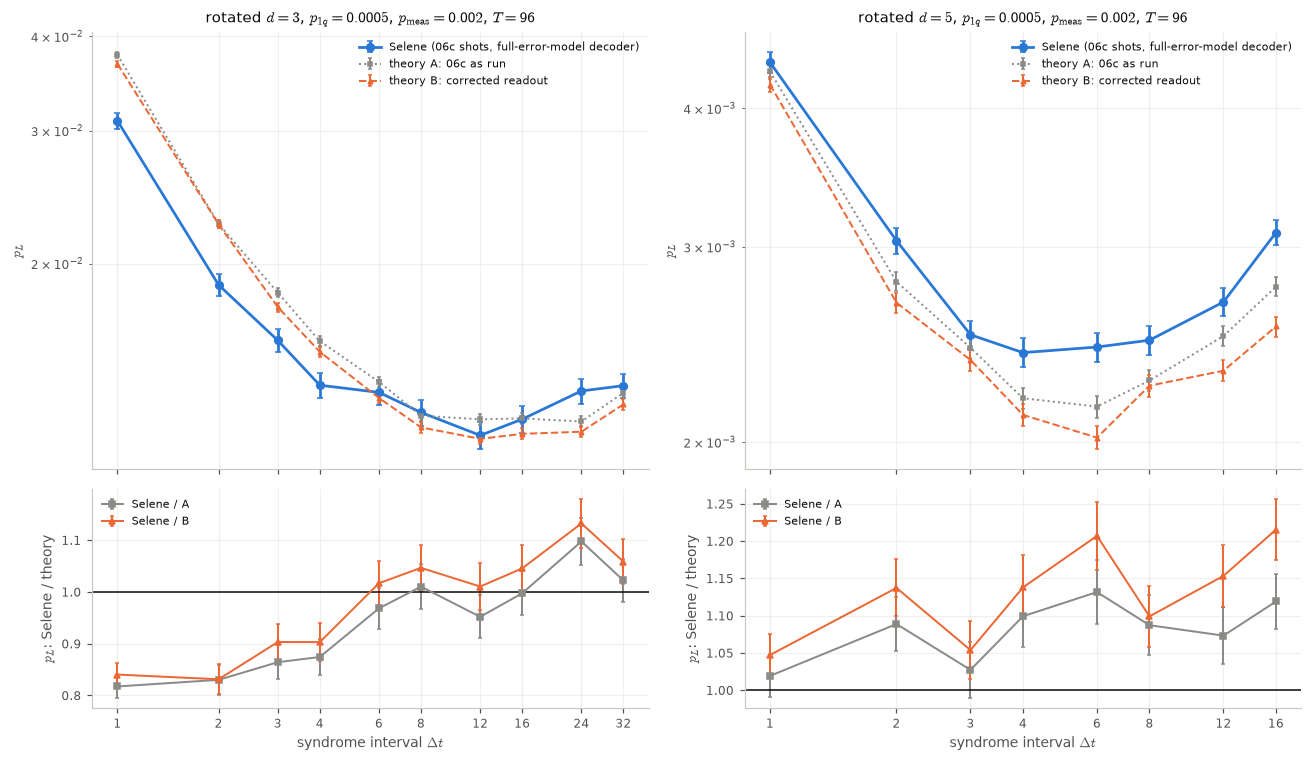

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex='col',
                         gridspec_kw={'height_ratios': [2, 1]})
for j, d in enumerate(SWEEP):
    taus, S, A, B = SWEEP[d]
    ax = axes[0, j]
    ax.errorbar(taus, S[:, 0], yerr=S[:, 1], marker='o', ms=5, lw=1.8, capsize=2, color=BLUE,
                label='Selene (06c shots, full-error-model decoder)')
    ax.errorbar(taus, A[:, 0], yerr=A[:, 1], marker='s', ms=3, lw=1.3, capsize=1.5, ls=':',
                color=GRAY, label='theory A: 06c as run')
    ax.errorbar(taus, B[:, 0], yerr=B[:, 1], marker='^', ms=3, lw=1.3, capsize=1.5, ls='--',
                color=ORANGE, label='theory B: corrected readout')
    ax.set_xscale('log', base=2); ax.set_yscale('log')
    ax.set_xticks(taus); ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
    ax.get_xaxis().set_minor_formatter(plt.NullFormatter())
    ax.grid(alpha=.6, which='both'); ax.set_axisbelow(True)
    ax.set_title(f'rotated $d={d}$, $p_{{1q}}={P_1Q}$, $p_\\mathrm{{meas}}={P_MEAS}$, $T={TOTAL}$')
    ax.set_ylabel(r'$p_L$'); ax.legend(fontsize=7)
    ax = axes[1, j]
    for X, col, mk, lab in ((A, GRAY, 's', 'Selene / A'), (B, ORANGE, '^', 'Selene / B')):
        r = S[:, 0] / X[:, 0]
        e = r * np.hypot(S[:, 1] / S[:, 0], X[:, 1] / X[:, 0])
        ax.errorbar(taus, r, yerr=e, marker=mk, ms=4, lw=1.3, capsize=1.5, color=col, label=lab)
    ax.axhline(1, color=INK, lw=1)
    ax.set_xlabel(r'syndrome interval $\Delta t$'); ax.set_ylabel(r'$p_L$: Selene / theory')
    ax.grid(alpha=.6); ax.set_axisbelow(True); ax.legend(fontsize=7)
finish(fig, '04d_theory_readout_corrected')

## 4b. How much of `p_L` comes from the final data readout alone?

The final data readout is one measurement layer, whatever Δt is, while the number of rounds is
`N = 96/Δt`. A flipped final data bit looks to the decoder exactly like an X fault on that qubit
just before readout, so it acts as one extra layer of data noise at the end. Its share of the
total noise therefore grows with Δt.

Theory C is theory B with the final data readout made **noiseless** (`p_final = 0`), everything
else identical. B − C is what the final readout's `p_meas` adds; B/C gives the fraction.
Same shots and seeds as §4.

In [9]:
rows, OPT_C = [], {}
for d, cfg in RUN.items():
    taus, S, A, B = SWEEP[d]
    Cv = np.array([theory('C', t, d, shots=cfg['shots']) for t in taus])
    SWEEP[d] = (taus, S, A, B, Cv)
    OPT_C[d] = optimum(taus, Cv[:, 0], Cv[:, 1], TOTAL)
    for t, b_, c_ in zip(taus, B, Cv):
        rows.append({'d': d, 'tau': t, 'R': TOTAL // t,
                     'B (final p_meas)': round(b_[0], 5), 'C (final noiseless)': round(c_[0], 5),
                     'B - C': round(b_[0] - c_[0], 5),
                     '(B-C)/sigma': round((b_[0] - c_[0]) / np.hypot(b_[1], c_[1]), 1),
                     'share of B': f"{100 * (b_[0] - c_[0]) / b_[0]:.1f}%"})
print(pd.DataFrame(rows).set_index(['d', 'tau']).to_string())
print()
for d in RUN:
    b, c = OPT[d]['theory B (corrected)'], OPT_C[d]
    print(f"d={d}: tau* with final readout p_meas = {b['tau* (fit)']} +/- {b['+/-']}, "
          f"noiseless = {c['tau* (fit)']} +/- {c['+/-']} "
          f"(lowest point {b['lowest tau']} vs {c['lowest tau']})")

        R  B (final p_meas)  C (final noiseless)    B - C  (B-C)/sigma share of B
d tau                                                                            
3 1    96           0.03679              0.03654  0.00025          0.5       0.7%
  2    48           0.02254              0.02226  0.00029          0.8       1.3%
  3    32           0.01751              0.01725  0.00026          0.8       1.5%
  4    24           0.01528              0.01496  0.00032          1.0       2.1%
  6    16           0.01327              0.01294  0.00034          1.1       2.5%
  8    12           0.01213              0.01171  0.00043          1.5       3.5%
  12    8           0.01172              0.01129  0.00042          1.5       3.6%
  16    6           0.01190              0.01137  0.00053          1.9       4.5%
  24    4           0.01197              0.01142  0.00055          2.0       4.6%
  32    3           0.01302              0.01226  0.00076          2.6       5.8%
5 1    96       

## 5. Q3 continued: does the theory track Selene as `p_meas` changes? (d = 3)

06c §2 swept `p_meas` = 0.0005, 0.001, 0.002, 0.005 in Selene (3 × 6,000 stored shots per point)
but compared only Δt\*. If `p_meas` is added to the model correctly, the **ratio** Selene / theory
should not drift with `p_meas`. Both theory versions, 3 × 100,000 shots per point.

In [10]:
TAUS3 = [t for t in range(1, TOTAL + 1) if TOTAL % t == 0 and TOTAL // t >= 3]
rows, PM = [], {}
for pm in (0.0005, 0.001, 0.002, 0.005):
    S = np.array([selene(t, 3, 6000, 3, p_meas=pm) for t in TAUS3])
    A = np.array([theory('A', t, 3, p_meas=pm) for t in TAUS3])
    B = np.array([theory('B', t, 3, p_meas=pm) for t in TAUS3])
    PM[pm] = (S, A, B)
    row = {'p_meas': pm}
    for lab, X in (('A', A), ('B', B)):
        r = S[:, 0] / X[:, 0]
        w = 1 / ((r * np.hypot(S[:, 1] / S[:, 0], X[:, 1] / X[:, 0])) ** 2)
        row[f'Selene/{lab}, weighted mean'] = round(float(np.sum(w * r) / np.sum(w)), 3)
        row[f'Selene/{lab}, tau=1'] = round(float(r[0]), 3)
        row[f'Selene/{lab}, tau=32'] = round(float(r[-1]), 3)
    row['theory B tau* (fit)'] = optimum(TAUS3, B[:, 0], B[:, 1], TOTAL)['tau* (fit)']
    row['Selene tau* (fit)'] = optimum(TAUS3, S[:, 0], S[:, 1], TOTAL)['tau* (fit)']
    rows.append(row)
PMT = pd.DataFrame(rows).set_index('p_meas')
print(PMT.to_string())

# drift of the ratio with p_meas: weighted linear fit of the per-p_meas weighted mean
for lab in ('A', 'B'):
    y = PMT[f'Selene/{lab}, weighted mean'].to_numpy()
    x = np.array(list(PM))
    k = np.polyfit(x, y, 1)[0]
    print(f"Selene/{lab}: changes by {k * (x[-1] - x[0]):+.3f} from p_meas = {x[0]} to {x[-1]}")

        Selene/A, weighted mean  Selene/A, tau=1  Selene/A, tau=32  Selene/B, weighted mean  Selene/B, tau=1  Selene/B, tau=32  theory B tau* (fit)  Selene tau* (fit)
p_meas                                                                                                                                                                
0.0005                    0.948            0.892             1.026                    0.972            0.904             1.089                13.10              11.82
0.0010                    0.919            0.875             1.015                    0.945            0.885             1.080                14.83              11.68
0.0020                    0.882            0.833             0.993                    0.911            0.856             1.029                14.91              11.71
0.0050                    0.876            0.922             0.948                    0.928            0.968             1.026                16.43              11.7

## 6. Findings

Each finding says where it comes from: **measured here**, **repo** (a choice made in this
repo's code), or **interpretation** (my reading, not tested).

**1. `p_meas` flips every recorded bit, including the final data readout.** (Measured here, §1.)
At `p_1q = 0`, `p_meas = 1`, all 3,200 ancilla bits and all 1,800 final data bits read 1.

**2. Selene runs are independent only if their seed ranges do not overlap.** (Measured here,
§1b.) Shot `k` is seeded with `random_seed + shot_offset + k`: after a one-shot shift, every
nonzero shot of the seed-2 run equals one of the seed-1 run. The first version of this notebook
compared seeds 1 and 2 and got χ²/dof of 0.1–0.6, because the "two" runs were nearly the same
shots. All runs here now use seed blocks 1,000,000 apart.
Consequences elsewhere (repo, not re-run here): 06c §2 ran all four `p_meas` values at seed 1
with the same offsets, so those four Selene curves share much of their gate noise (a run with
`p_meas` changed at the same seed still shares gate faults: about 2.2× the chance coincidence
rate, measured while diagnosing this). Blocks at different offsets of one seed, as in 06b/06c,
do not overlap and are independent.

**3. Turning `p_meas` on does not change what a round costs the data.** (Measured here, §2.)
With `p_meas = 0.02`, once the final readout flip is undone, the cost per round is 6.86 against
04's 6.89 (d = 3) and 8.34 against 8.40 (d = 5): differences of −0.14 and −0.36 standard errors. Left
uncorrected, the readout flip appears entirely in the **intercept** (30 ops, matching
`n_eff(0.02)` = 30.6), not the slope. So λ = 1/`n_data` and `p` from 04 are valid with
`p_meas` on. The per-point χ²/dof is 1.41 and 1.31 (nominal p = 0.035 and 0.012), with a small
constant offset across N at d = 3. Interpretation, not tested: each run uses one seed for all
five N, and the first round's faults are drawn identically at every N, so the points are not
independent and the nominal p-values are too small.

**4. The recorded syndrome bit is the ancilla's gate faults XOR `p_meas`.** (Measured here,
§3.) The rule 05 and 06c use, `1 − (1 − p_meas)(1 − p_anc)`, counts a double flip as an error.
In fact two flips cancel. At `p_meas = 0.3` that rule misses each Z-ancilla by 6.7σ on average at
d = 5 (χ²/dof 53), while XOR fits (χ²/dof 0.99). Over all four `p_meas` values XOR gives χ²/dof 1.6 (d = 3, 16 dof) and
1.08 (d = 5, 48 dof). At 06c's operating point the two rules differ by `p_anc·p_meas` ≈ 6×10⁻⁶,
so **no published number in 05 or 06c changes because of this**. It is a correctness fix.

**5. 06c's theory gave the final data readout too much error; fixing it lowers the theory by
about 4%.** (Repo issue found here; effect measured here, §4.) 06c used Stim's
`before_measure_flip_probability`, which puts the syndrome rate `p_read` ≈ 0.005 on the final
data readout too. In Selene the data are measured directly, so only `p_meas` = 0.002 belongs
there. Corrected, the theory `p_L` drops by 0.1–7.9% (consistently, at all 18 points).
- d = 3: theory Δt\* 16.7 ± 2.3 → 14.9 ± 1.4; Selene 12.0 ± 0.85. Gap 2.0σ → 1.8σ.
- d = 5: theory Δt\* 5.67 ± 0.21 → 5.91 ± 0.53; Selene 5.08 ± 0.37. Gap 1.4σ → 1.3σ.
- Selene / theory becomes 0.83–1.13 at d = 3 and 1.05–1.22 at d = 5 (06c quoted 0.82–1.10 and
  1.02–1.13). The model now sits **below** Selene by 5–22% at d = 5.

06c's conclusions (an interior optimum at both distances; the paper's model within about 1.5σ of
Selene's Δt\*) stand.

**5b. The final data readout's own error adds a few percent to `p_L`, most at long Δt, and
barely moves Δt\*.** (Measured here, §4b; theory only.) Making that one readout noiseless lowers
`p_L` by 0.7% at Δt = 1 rising to 5.8% at Δt = 32 (d = 3), and 0.4% to 3.7% at d = 5. The sign is
the same at all 18 points and the share grows with Δt, as expected for one fixed layer against
N = 96/Δt rounds. Δt\* moves from 14.9 ± 1.4 to 15.5 ± 1.6 (d = 3) and 5.91 ± 0.53 to
5.98 ± 0.53 (d = 5): both well inside the error. Interpretation: the decoder treats a flipped
final data bit like an X fault just before readout and corrects it as one, so it costs far less
than its raw rate.

**6. Open: the model says more readout error should lengthen Δt\*; Selene shows no shift.**
(Measured here, §5.) From `p_meas` = 0.0005 to 0.005 the corrected theory's Δt\* goes 13.1 →
16.4; Selene's stays at 11.7–11.8. The Selene / theory ratio drifts by −0.033 (corrected) and
−0.061 (06c's version), so the correction halves the drift but does not remove it. Two possible
explanations, neither tested: the phenomenological model overstates what readout error costs in
this circuit, or the shared seeds in 06c's sweep (finding 2) make its four curves too alike. A
re-run of that sweep with disjoint seeds would separate the two.

### Limits

- Rotated d = 3 and 5 only, `p_2q = 0`.
- §3 uses each Z-ancilla's **raw** rate, which includes data faults that propagated onto it. The
  conditioned rate 04 exports (`n_anc`) was not re-measured with `p_meas` on, because its
  conditioning (data reading 0) itself changes when `p_meas` flips the data readout.
- The correction in §4 touches only the readout. The other gaps between the model and Selene
  (one scalar `p_stab` for all data qubits, no faults partway through extraction) are untouched.
- 05 and 06c themselves have **not** been edited.

### Next

1. Decide whether to carry the two corrections (XOR, `p_meas` on the final data readout) into
   05 and 06c.
2. Re-run 06c's `p_meas` sweep with disjoint seed blocks, to settle finding 6.
3. Check other places where runs that are compared share a seed range (04's five N values per
   code are one example).